# MONSTER test folds

The final benchmark: all 26 MONSTER datasets, each model's fold-0 pick frozen
and trained once on each of the five folds, scored once on the held-out fold
(README `m3`, "The test folds" and "QUANT's ExtraTrees on the same folds";
`scripts/m3_runs/test_runs.py`, `et_runs.py`). Nothing here trains anything; it
reads `results/test/fold{0-4}` and writes the paper's MONSTER figures.

One run is replaced. XGBoost's intercept estimate failed on WISDM's fold 3, a
fold that holds every series of two classes, and `results/test/repaired` holds
that fold rerun with `--base-score 0.5`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.transforms import Bbox
from scipy import stats

RESULTS = Path("../results/test")
FIGURES = Path("../paper/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

MODELS = ["hashboost", "xgboost", "extratrees"]
NAMES = {"hashboost": "HashBoost", "xgboost": "XGBoost", "extratrees": "ExtraTrees"}


def engine(label):
    return (
        "hashboost"
        if label.startswith("hb_")
        else "xgboost"
        if label.startswith("xgb")
        else "extratrees"
    )


def training_s(entry):
    """QUANT plus training: XGBoost's build is its QUANT pass, HashBoost's QUANT is in its training."""

    return sum(
        t["wall_s"] for t in entry["timings"] if t["phase"] in ("build", "train")
    )


rows, entries = [], {}
for fold in range(5):
    for path in sorted((RESULTS / f"fold{fold}").glob("*.json")):
        run = json.loads(path.read_text())
        for label, entry in run["models"].items():
            entries[run["dataset"], fold, engine(label)] = entry
# The repaired rerun replaces the failed run's error, not its time: it ran on
# the RTX 4060, so the L40S run's training seconds stand.
l40s_seconds = {}
for path in sorted((RESULTS / "repaired").glob("*.json")):
    run = json.loads(path.read_text())
    for label, entry in run["models"].items():
        key = run["dataset"], run["split"]["fold"], engine(label)
        l40s_seconds[key] = training_s(entries[key])
        entries[key] = entry

for (dataset, fold, model), entry in entries.items():
    rows.append(
        {
            "dataset": dataset,
            "fold": fold,
            "model": model,
            "test": entry["test"]["merror"],
            "va": entry["tuned"],
            "seconds": l40s_seconds.get((dataset, fold, model), training_s(entry)),
        }
    )

runs = pd.DataFrame(rows)
assert len(runs) == 26 * 5 * 3, len(runs)
error = runs.pivot_table(index="dataset", columns="model", values="test")[MODELS]
seconds = runs.pivot_table(
    index="dataset", columns="model", values="seconds", aggfunc="sum"
)[MODELS]
error.round(4)

model,hashboost,xgboost,extratrees
dataset,,,
AudioMNIST-DS,0.0816,0.0884,0.1270
CornellWhaleChallenge,0.1250,0.1233,0.1262
CrowdSourced,0.3501,0.3622,0.3396
DREAMERA,0.5161,0.5312,0.4867
DREAMERV,0.4036,0.4038,0.4179
FordChallenge,0.0823,0.0731,0.0715
FruitFlies,0.0458,0.0462,0.0619
InsectSound,0.1872,0.1891,0.2268
LakeIce,0.0018,0.0019,0.0024


## Style

The palette from `ucr.ipynb`.

In [2]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#8a8880"
GRID = "#e6e5e1"

BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"

COLOURS = {"hashboost": BLUE, "extratrees": ORANGE, "xgboost": AQUA}

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.labelsize": 9,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "lines.linewidth": 2.0,
        "lines.solid_capstyle": "round",
        "lines.solid_joinstyle": "round",
        "figure.dpi": 120,
        "pdf.fonttype": 42,
    }
)


def finish(ax, title=None, note=None, xlabel=None, ylabel=None):
    """Title, optional sub-note, recessive chrome."""

    if title:
        ax.set_title(title, pad=16 if note else 8)
    if note:
        ax.text(
            0.0,
            1.02,
            note,
            transform=ax.transAxes,
            fontsize=8.5,
            color=INK_2,
            va="bottom",
        )
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    return ax


def dot(ax, x, y, colour, size=6, **kwargs):
    """A marker with a surface ring, so overlapping points stay legible."""

    ax.plot(
        x,
        y,
        "o",
        color=colour,
        markersize=size,
        markeredgecolor=SURFACE,
        markeredgewidth=1.2,
        linestyle="none",
        zorder=4,
        **kwargs,
    )


def save(fig, name):
    """Export a figure for the paper, beside showing it here.

    Without a creation date the PDF is the same bytes on every run, so
    rerunning the notebook only changes the figures whose content changed.
    """

    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        FIGURES / f"{name}.pdf", bbox_inches="tight", metadata={"CreationDate": None}
    )


NEAR = ((8, 4), (8, -12), (-8, 4), (-8, -12))
FAR = ((8, 16), (8, -24), (-8, 16), (-8, -24))


def place_labels(ax, items, points, offsets=NEAR + FAR):
    """Name a few points without covering any: each label takes the first free spot.

    `items` is (x, y, text) for the points to name, and `points` is (x, y) for
    every point drawn, all of which a label must keep clear of, as it must of
    the axis edges and the labels already placed. A label with no free spot is
    left off; the tables carry every value. Call it once the layout is final,
    because it works in pixels.
    """

    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    frame = ax.get_window_extent(renderer)

    def around(x, y, half=6):
        px, py = ax.transData.transform((x, y))
        return Bbox.from_extents(px - half, py - half, px + half, py + half)

    taken = [around(x, y) for x, y in points]

    for x, y, text in items:
        for dx, dy in offsets:
            label = ax.annotate(
                text,
                (x, y),
                textcoords="offset points",
                xytext=(dx, dy),
                ha="left" if dx > 0 else "right",
                fontsize=7.5,
                color=INK_2,
                zorder=5,
            )
            box = label.get_window_extent(renderer).expanded(1.04, 1.15)

            within = frame.contains(box.x0, box.y0) and frame.contains(box.x1, box.y1)

            if within and not any(box.overlaps(other) for other in taken):
                taken.append(box)
                break

            label.remove()

## Pairwise comparisons

The ratio is the geometric mean of the first model's error over the second's.
A dataset is a clear win when a 95% paired-t interval over its five per-fold
differences excludes zero. Wilcoxon on the five-fold means, Holm over the three
comparisons.

In [3]:
folds = runs.pivot_table(index=["dataset", "fold"], columns="model", values="test")
T = stats.t.ppf(0.975, 4)

out = []
for a, b in (
    ("hashboost", "xgboost"),
    ("hashboost", "extratrees"),
    ("xgboost", "extratrees"),
):
    d = (folds[a] - folds[b]).groupby("dataset")
    half = T * d.std() / np.sqrt(5)
    out.append(
        {
            "comparison": f"{NAMES[a]} vs {NAMES[b]}",
            "ratio": np.exp(np.log(error[a] / error[b]).mean()),
            "W/T/L": f"{(error[a] < error[b]).sum()}/{(error[a] == error[b]).sum()}/{(error[a] > error[b]).sum()}",
            "clear W/L": f"{(d.mean() < -half).sum()}/{(d.mean() > half).sum()}",
            "p": stats.wilcoxon(error[a], error[b]).pvalue,
        }
    )
pairs = pd.DataFrame(out)
order = pairs["p"].sort_values().index
pairs.loc[order, "p_holm"] = np.minimum(
    1, np.maximum.accumulate(pairs.loc[order, "p"] * np.arange(3, 0, -1))
)
pairs.round(3)

,comparison,ratio,W/T/L,clear W/L,p,p_holm
0,HashBoost vs XGBoost,1.016,14/0/12,1/6,0.980,0.980
1,HashBoost vs ExtraTrees,0.904,18/0/8,9/5,0.056,0.112
2,XGBoost vs ExtraTrees,0.890,20/0/6,13/3,0.010,0.031


## Average ranks

Demšar's Friedman test and Nemenyi critical difference, drawn as for UCR.

Friedman p = 0.016, Nemenyi CD = 0.650 over 26 datasets


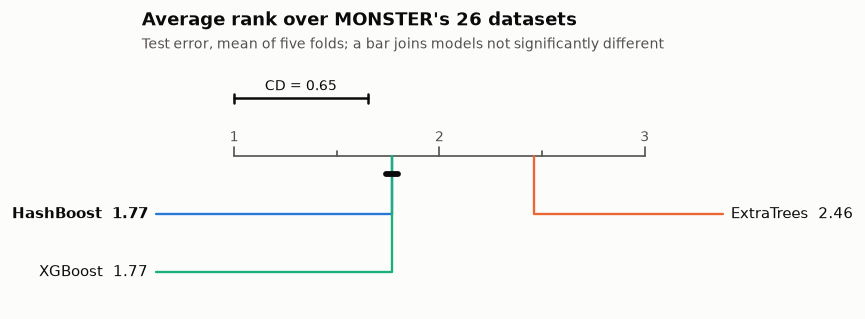

In [4]:
# Demšar (2006), Table 5(a): two-tailed Nemenyi critical values at alpha = 0.05
Q_05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728}


def friedman(errors):
    """-> (average ranks, Friedman p-value, Nemenyi critical difference)."""

    n, k = errors.shape
    ranks = errors.rank(axis=1, method="average").mean().sort_values()

    _, p = stats.friedmanchisquare(*(errors[c] for c in errors.columns))

    return ranks, p, Q_05[k] * np.sqrt(k * (k + 1) / (6 * n))


def cliques(ranks, cd):
    """Maximal runs of rank-sorted models spanning less than one CD."""

    values = ranks.to_numpy()
    runs = []

    for i in range(len(values)):
        j = i
        while j + 1 < len(values) and values[j + 1] - values[i] < cd:
            j += 1
        if j > i and not any(a <= i and j <= b for a, b in runs):
            runs.append((i, j))

    return runs


def cd_diagram(ranks, cd, title, note):
    """Average ranks on one axis, rank 1 (lowest error) on the left."""

    k = len(ranks)
    fig, ax = plt.subplots(figsize=(6.4, 2.3 + 0.3 * k))

    ax.set_xlim(0.55, k + 0.45)
    ax.set_ylim(-(k // 2 + 1.6), 2.5)
    ax.axis("off")

    ax.plot([1, k], [0, 0], color=INK_2, lw=1)

    for tick in np.arange(1, k + 0.01, 0.5):
        whole = float(tick).is_integer()
        ax.plot([tick, tick], [0, 0.16 if whole else 0.09], color=INK_2, lw=1)
        if whole:
            ax.text(tick, 0.26, f"{tick:.0f}", ha="center", fontsize=8.5, color=INK_2)

    # the CD itself, as a length on the rank axis
    ax.plot([1, 1 + cd], [1.0, 1.0], color=INK, lw=1.5)
    for end in (1, 1 + cd):
        ax.plot([end, end], [0.92, 1.08], color=INK, lw=1.5)
    ax.text(1 + cd / 2, 1.14, f"CD = {cd:.2f}", ha="center", fontsize=8.5, color=INK)

    half = (k + 1) // 2

    for i, (model, rank) in enumerate(ranks.items()):
        left = i < half
        depth = -(i + 1) if left else -(k - i)
        edge = 0.62 if left else k + 0.38
        colour = COLOURS.get(model, INK_2)

        ax.plot([rank, rank, edge], [0, depth, depth], color=colour, lw=1.4)
        ax.text(
            edge + (-0.04 if left else 0.04),
            depth,
            f"{NAMES[model]}  {rank:.2f}",
            ha="right" if left else "left",
            va="center",
            fontsize=9,
            color=INK,
            fontweight="bold" if model == "hashboost" else "normal",
        )

    for step, (a, b) in enumerate(cliques(ranks, cd)):
        y = -0.3 - 0.22 * step
        ax.plot([ranks.iloc[a] - 0.03, ranks.iloc[b] + 0.03], [y, y], color=INK, lw=3.5)

    ax.text(0.55, 2.5, title, fontsize=11, fontweight="bold", color=INK, va="top")
    ax.text(0.55, 2.05, note, fontsize=8.5, color=INK_2, va="top")

    return fig


ranks, p, cd = friedman(error)
print(f"Friedman p = {p:.2g}, Nemenyi CD = {cd:.3f} over {len(error)} datasets")

fig = cd_diagram(
    ranks,
    cd,
    "Average rank over MONSTER's 26 datasets",
    "Test error, mean of five folds; a bar joins models not significantly different",
)
fig.savefig(FIGURES / "monster_cd.pdf", bbox_inches="tight")

## HashBoost against each baseline

One point per dataset; below the diagonal, HashBoost has the lower error.

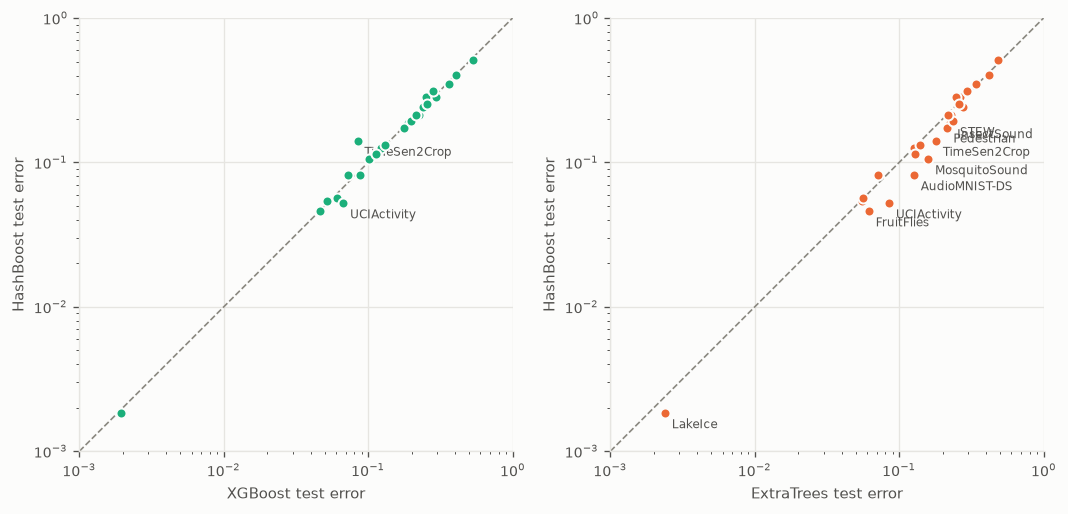

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.4))

for ax, other in zip(axes, ("xgboost", "extratrees")):
    ax.plot([1e-3, 1], [1e-3, 1], color=MUTED, lw=1, ls="--", zorder=1)
    for dataset, r in error.iterrows():
        dot(ax, r[other], r["hashboost"], COLOURS[other])
        if abs(np.log(r["hashboost"] / r[other])) > np.log(1.2):
            ax.annotate(
                dataset,
                (r[other], r["hashboost"]),
                fontsize=7,
                color=INK_2,
                xytext=(4, -9),
                textcoords="offset points",
            )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1e-3, 1)
    ax.set_ylim(1e-3, 1)
    ax.set_aspect("equal")
    finish(ax, xlabel=f"{NAMES[other]} test error", ylabel="HashBoost test error")

fig.tight_layout()
fig.savefig(FIGURES / "monster_scatter.pdf", bbox_inches="tight")

## Validation error against training time

Fold 0, the six largest pools, each booster at its frozen pick. HashBoost's
time is measured at every evaluation (its `timeline`). XGBoost's is its build
plus its mean seconds per round times the round, because its rounds cost close
to the same each. The ring marks the round tune error chose. Both include QUANT.

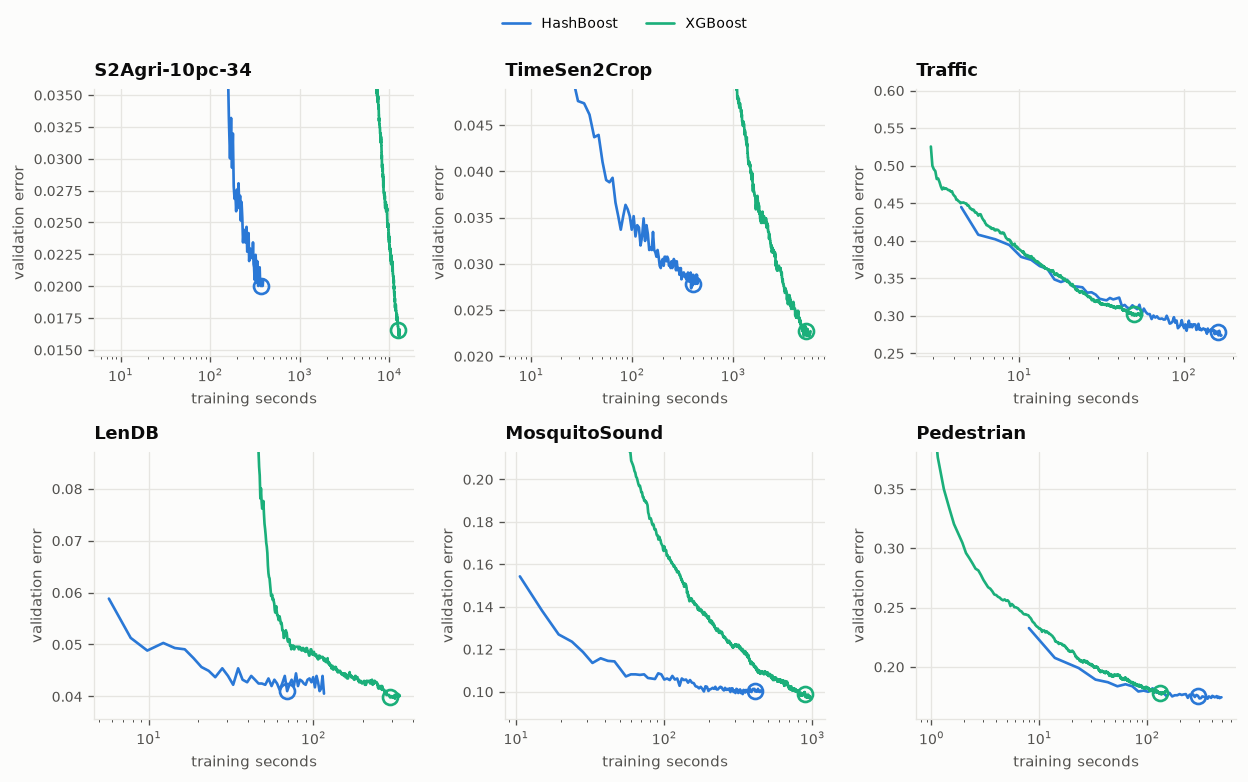

In [6]:
SHOW = [
    "S2Agri-10pc-34",
    "TimeSen2Crop",
    "Traffic",
    "LenDB",
    "MosquitoSound",
    "Pedestrian",
]

fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.2))

for ax, dataset in zip(axes.flat, SHOW):
    hb = entries[dataset, 0, "hashboost"]
    xg = entries[dataset, 0, "xgboost"]

    va = hb["results"]["va"]["merror"]
    clock = {t["round"]: t["wall_s"] for t in hb["timeline"]}
    t_hb = np.array([clock[r] for r in va["x"]])
    ax.plot(t_hb, va["y"], color=COLOURS["hashboost"], lw=1.6, label="HashBoost")
    i = va["x"].index(hb["best_round"])
    ax.plot(
        t_hb[i], va["y"][i], "o", mfc="none", mec=COLOURS["hashboost"], ms=9, mew=1.6
    )

    vx = xg["results"]["va"]["merror"]["y"]
    build = xg["timings"][0]["wall_s"]
    t_xg = build + xg["seconds_per_round"] * (np.arange(len(vx)) + 1)
    ax.plot(t_xg, vx, color=COLOURS["xgboost"], lw=1.6, label="XGBoost")
    j = xg["best_iteration"]
    ax.plot(t_xg[j], vx[j], "o", mfc="none", mec=COLOURS["xgboost"], ms=9, mew=1.6)

    lo = min(min(va["y"]), min(vx))
    ax.set_ylim(lo * 0.9, lo * 2.2)
    ax.set_xscale("log")
    finish(ax, title=dataset, xlabel="training seconds", ylabel="validation error")

fig.tight_layout()
# one legend above the grid, since a corner inside a panel lands on some curve
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.savefig(FIGURES / "monster_time.pdf", bbox_inches="tight")

## Where HashBoost is faster, and what XGBoost reaches in the same time

HashBoost's cost is set by its round budget; XGBoost's per round grows with
rows x features x classes (one tree per class per round over the binned
matrix). Left: each dataset's speedup (XGBoost's training time over
HashBoost's, summed over the five folds) against that product. Right, a
time-matched comparison on validation error: on each fold, XGBoost is cut off
at HashBoost's *total* training time (patience included), and its round is
chosen on tune error among the rounds it finished by then. XGBoost's clock is
its build plus its mean seconds per round. Test error was only scored at each
model's own chosen round, so this one is validation error.

In [7]:
sizes = {}
for path in sorted((RESULTS / "fold0").glob("*.json")):
    run = json.loads(path.read_text())
    split = run["split"]
    sizes[run["dataset"]] = (
        split["n_tr"] * run["transform"]["num_features"] * split["num_classes"]
    )


def at_time(xgb, seconds):
    """XGBoost's tune-chosen validation error among the rounds done by `seconds`."""

    done = int((seconds - xgb["timings"][0]["wall_s"]) // xgb["seconds_per_round"])
    if done < 1:
        return np.nan
    tune = xgb["results"]["tune"]["merror"]["y"][:done]
    return xgb["results"]["va"]["merror"]["y"][int(np.argmin(tune))]


rows = []
for dataset in error.index:
    hb = [entries[dataset, fold, "hashboost"] for fold in range(5)]
    xg = [entries[dataset, fold, "xgboost"] for fold in range(5)]
    rows.append(
        {
            "dataset": dataset,
            "cost": sizes[dataset],
            "speedup": seconds.loc[dataset, "xgboost"]
            / seconds.loc[dataset, "hashboost"],
            "hb_va": np.mean([h["tuned"] for h in hb]),
            "xgb_va_matched": np.mean(
                [at_time(x, training_s(h)) for h, x in zip(hb, xg)]
            ),
            "xgb_va_final": np.mean([x["tuned"] for x in xg]),
        }
    )
speed = pd.DataFrame(rows).set_index("dataset").sort_values("cost")

rho, p_rho = stats.spearmanr(speed["cost"], speed["speedup"])
lower = (speed["hb_va"] < speed["xgb_va_matched"]).sum()
print(
    f"speedup: median {speed['speedup'].median():.2f}, faster on {(speed['speedup'] > 1).sum()}/26, "
    f"Spearman with cost {rho:.2f} (p = {p_rho:.1g})"
)
print(
    f"time-matched: HashBoost lower on {lower}/26, geo ratio XGBoost/HashBoost "
    f"{np.exp(np.log(speed['xgb_va_matched'] / speed['hb_va']).mean()):.2f}"
)
speed.round(4)

speedup: median 1.23, faster on 14/26, Spearman with cost 0.87 (p = 7e-09)
time-matched: HashBoost lower on 19/26, geo ratio XGBoost/HashBoost 1.35


,cost,speedup,hb_va,xgb_va_matched,xgb_va_final
dataset,,,,,
WISDM,134949420,0.1355,0.0099,0.0128,0.0128
UCIActivity,296913600,0.2756,0.0096,0.0170,0.0170
CrowdSourced,357938616,0.4945,0.0033,0.0048,0.0048
LakeIce,471969792,0.1944,0.0018,0.0020,0.0020
FordChallenge,588118860,0.7744,0.0556,0.0354,0.0354
STEW,832204128,0.9541,0.0348,0.0264,0.0265
CornellWhaleChallenge,1117593984,1.4625,0.1292,0.1304,0.1297
Tiselac,1316687400,0.6763,0.0484,0.0520,0.0520
WISDM2,1686201912,0.4510,0.0274,0.0180,0.0180


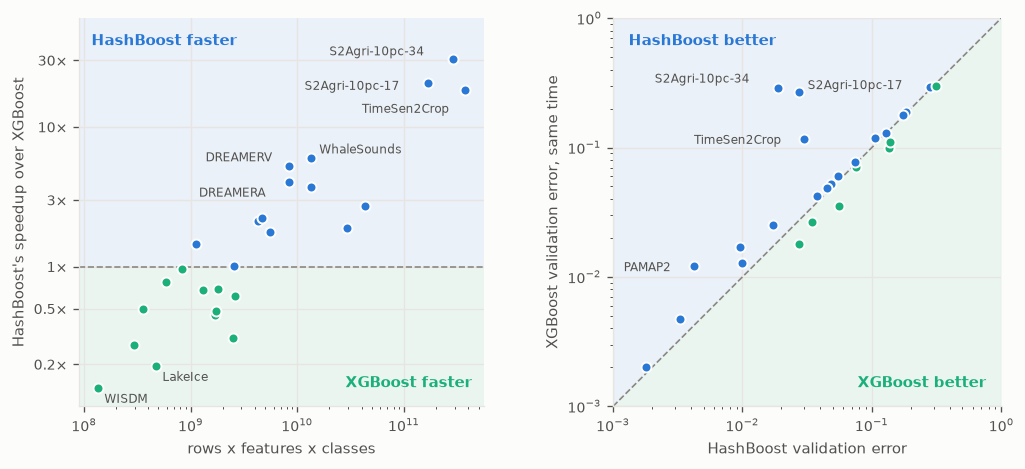

In [8]:
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), gridspec_kw={"wspace": 0.3})
HB, XGB = COLOURS["hashboost"], COLOURS["xgboost"]
TINT = 0.08


def region_label(ax, x, y, text, colour, **kwargs):
    """Name a shaded region in its own colour, so the plot reads without the caption."""

    ax.text(
        x,
        y,
        text,
        transform=ax.transAxes,
        fontsize=9,
        fontweight="bold",
        color=colour,
        zorder=5,
        **kwargs,
    )


# label offsets in points, so the crowded top-right points stay legible
LEFT = {
    "S2Agri-10pc-34": (-74, 2),
    "S2Agri-10pc-17": (-74, -4),
    "TimeSen2Crop": (-62, -14),
    "WhaleSounds": (5, 3),
    "DREAMERV": (-50, 3),
    "DREAMERA": (-54, -9),
}
RIGHT = {
    "S2Agri-10pc-34": (-74, 3),
    "S2Agri-10pc-17": (5, 2),
    "TimeSen2Crop": (-66, -3),
    "PAMAP2": (-42, -3),
}

# left: training speedup. Above 1 HashBoost trained faster.
ax = axes[0]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(0.1, 60)
ax.axhspan(1, 60, color=HB, alpha=TINT, lw=0, zorder=0)
ax.axhspan(0.1, 1, color=XGB, alpha=TINT, lw=0, zorder=0)
ax.axhline(1, color=MUTED, lw=1, ls="--", zorder=1)
for dataset, r in speed.iterrows():
    dot(ax, r["cost"], r["speedup"], HB if r["speedup"] > 1 else XGB)
    if r["speedup"] > 4 or r["speedup"] < 0.25:
        ax.annotate(
            dataset,
            (r["cost"], r["speedup"]),
            fontsize=7,
            color=INK_2,
            xytext=LEFT.get(dataset, (4, -9)),
            textcoords="offset points",
        )
ax.yaxis.set_major_locator(FixedLocator([0.2, 0.5, 1, 3, 10, 30]))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}×"))
region_label(ax, 0.03, 0.96, "HashBoost faster", HB, ha="left", va="top")
region_label(ax, 0.97, 0.04, "XGBoost faster", XGB, ha="right", va="bottom")
finish(
    ax,
    xlabel="rows x features x classes",
    ylabel="HashBoost's speedup over XGBoost",
)

# right: error at equal time. Above the diagonal XGBoost's error is the higher one.
ax = axes[1]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1e-3, 1)
ax.set_ylim(1e-3, 1)
ax.set_aspect("equal")
edge = np.array([1e-3, 1])
ax.fill_between(edge, edge, 1, color=HB, alpha=TINT, lw=0, zorder=0)
ax.fill_between(edge, 1e-3, edge, color=XGB, alpha=TINT, lw=0, zorder=0)
ax.plot(edge, edge, color=MUTED, lw=1, ls="--", zorder=1)
matched = speed.dropna(subset=["xgb_va_matched"])
for dataset, r in matched.iterrows():
    hb_wins = r["xgb_va_matched"] > r["hb_va"]
    dot(ax, r["hb_va"], r["xgb_va_matched"], HB if hb_wins else XGB)
    if r["xgb_va_matched"] / r["hb_va"] > 2.5:
        ax.annotate(
            dataset,
            (r["hb_va"], r["xgb_va_matched"]),
            fontsize=7,
            color=INK_2,
            xytext=RIGHT.get(dataset, (4, -9)),
            textcoords="offset points",
        )
region_label(ax, 0.04, 0.96, "HashBoost better", HB, ha="left", va="top")
region_label(ax, 0.96, 0.04, "XGBoost better", XGB, ha="right", va="bottom")
finish(
    ax,
    xlabel="HashBoost validation error",
    ylabel="XGBoost validation error, same time",
)

save(fig, "monster_speed")